# ConformAtlas Python API walkthrough: influenza neuraminidase with zanamivir

This notebook runs the ConformAtlas building blocks from Python on the fixture shipped
with the test suite: `tests/data/h1n1_ca` — influenza A/H1N1 neuraminidase Cα atoms plus the
heavy atoms of bound zanamivir (ZMR), 81 frames at 250 ps spacing (20 ns). It is a *small*
fixture: with 81 frames and ~3 effective samples along PC1 the landscape is **not** converged,
and the notebook says so where it matters. The point is the workflow, not the biology.

Units throughout: Å (coordinates, projections), ps (time), kJ/mol (free energies), K;
R = 0.008314462618 kJ/(mol K).

Steps:

1. `api.load_trajectories` — superposed coordinates of the analysis group
2. `api.pca` — Cartesian PCA (equal-replicate weighting)
3. `api.landscape` — Boltzmann-inverted ΔG(PC1, PC2)
4. `api.states` — watershed basins, populations, barriers
5. `api.kinetics`, `api.convergence`
6. memory-lean streaming PCA (`conformatlas.streaming`) and the MDAnalysis `AnalysisBase` class
7. the full pipeline (`api.analyze`), the HDF5 results container and `rebin`


In [ ]:
import os, tempfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["CONFORMATLAS_NO_PROGRESS"] = "1"  # progress bars are TTY-only anyway

import conformatlas
from conformatlas import api

# locate the repository root (works from examples/notebooks/ or the repo root)
here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "tests" / "data" / "h1n1_ca").is_dir())
DATA = ROOT / "tests" / "data" / "h1n1_ca"
TOPO, TRAJ, NDX = DATA / "neuraminidase_ca.pdb", DATA / "neuraminidase_ca.xtc", DATA / "index.ndx"
print(conformatlas.__version__, DATA)

## 1. Load and superpose

`load_trajectories` resolves the analysis group (`C-alpha` from the index file, plus the ligand
residue `ZMR`), fits every frame onto the reference structure with the Cα atoms (Kabsch), and
keeps the fitted analysis-group coordinates in memory (float32, Å).

In [2]:
ens = api.load_trajectories(TOPO, [TRAJ], group="C-alpha", lig_group="ZMR", index_file=NDX)
print(f"{ens.n_frames} frames, {ens.n_atoms} analysis atoms ({int(ens.ligand_mask.sum())} ligand), dt = {ens.dt_ps:.0f} ps")
ens.atom_info.head()

81 frames, 411 analysis atoms (24 ligand), dt = 250 ps
Out[2]: 
   atom_index chain  residue_number residue_name atom_name    mass
0           0     A               1          SER        CA  12.011
1           1     A               2          VAL        CA  12.011
2           2     A               3          LYS        CA  12.011
3           3     A               4          LEU        CA  12.011
4           4     A               5          ALA        CA  12.011


,atom_index,chain,residue_number,residue_name,atom_name,mass
0,0,A,1,SER,CA,12.011
1,1,A,2,VAL,CA,12.011
2,2,A,3,LYS,CA,12.011
3,3,A,4,LEU,CA,12.011
4,4,A,5,ALA,CA,12.011


## 2. Cartesian PCA

Eigenvalues are variances along each component (Å²). With one replicate the two weighting
schemes coincide.

In [3]:
pcs = api.pca(ens, n_components=10, weighting="equal-replicate")
scree = pd.DataFrame({"eigenvalue_A2": pcs.eigenvalues, "explained_%": pcs.explained_variance,
                      "cumulative_%": pcs.cumulative_variance}, index=[f"PC{i+1}" for i in range(10)])
scree.round(2)

Out[3]: 
      eigenvalue_A2  explained_%  cumulative_%
PC1          110.31        25.88         25.88
PC2           51.70        12.13         38.00
PC3           28.18         6.61         44.61
PC4           19.92         4.67         49.29
PC5           16.21         3.80         53.09
PC6           14.88         3.49         56.58
PC7           10.24         2.40         58.98
PC8           10.02         2.35         61.33
PC9            8.57         2.01         63.34
PC10           7.44         1.75         65.09


,eigenvalue_A2,explained_%,cumulative_%
PC1,110.31,25.88,25.88
PC2,51.70,12.13,38.00
PC3,28.18,6.61,44.61
PC4,19.92,4.67,49.29
PC5,16.21,3.80,53.09
PC6,14.88,3.49,56.58
PC7,10.24,2.40,58.98
PC8,10.02,2.35,61.33
PC9,8.57,2.01,63.34
PC10,7.44,1.75,65.09


## 3. Free-energy landscape

ΔG(x, y) = −RT ln(P(x, y)/P_max) on a square histogram of (PC1, PC2). 81 frames only support a
coarse grid; 12 × 12 bins follow the test suite. Unsampled bins are NaN (grey).

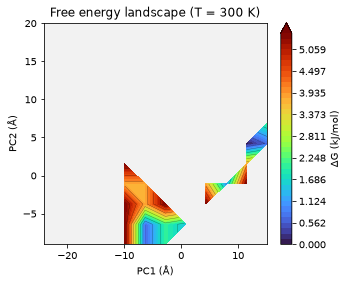

In [4]:
land = api.landscape(pcs, temperature=300.0, bins=12)
fig, ax, mappable = api.plot_landscape(land)
fig.set_size_inches(5, 4); fig.set_dpi(72)
plt.show()

## 4. States

Watershed segmentation of ΔG seeded at local probability maxima; basins separated by a saddle
lower than 1 kT are merged; basins holding ≥ 5 % of the frames are reported as states.

In [5]:
st = api.states(land, min_population=0.05)
display(st.populations().round(3))
print(f"unassigned / minor: {st.unassigned_population*100:.1f}%")
st.barriers.round(2)

unassigned / minor: 13.6%
Out[5]: 
Empty DataFrame
Columns: [state_i, state_j, saddle_kJ_mol, barrier_from_i_kJ_mol, barrier_from_j_kJ_mol]
Index: []


,state,population,min_cv1,min_cv2,min_free_energy_kJ_mol
0,State A,0.469,-6.328,-9.038,0.627
1,State B,0.395,11.479,4.195,-0.000


,state_i,state_j,saddle_kJ_mol,barrier_from_i_kJ_mol,barrier_from_j_kJ_mol


## 5. Kinetics and convergence

Transition counts are taken between consecutive major-state frames; mean first-passage times
assume a Markov chain at lag one frame (250 ps) and are indicative only. The convergence block
reports half-vs-half RMSIP, cosine content and the effective sample size — read the notes.

In [6]:
kin = api.kinetics(st)
display(kin["dwell_summary"].round(2))
conv = api.convergence(ens, pcs, st)
print(conv.sampling_assessment)
for note in conv.assessment_notes:
    print(" -", note)

Insufficient evidence
 - Effective number of independent samples along PC1/PC2: 3 of 81 frames (statistical inefficiency Rep_1: g=26.3 frames).
 - Fewer than 50 effective samples: populations and free energies are not statistically reliable regardless of the other diagnostics.
 - Low subspace overlap between the first and second halves of the replicates (RMSIP = 0.39; heuristic: >= 0.70 high, 0.50-0.70 moderate, < 0.50 low).
 - High PC1 cosine content (0.92 >= 0.70): PC1 resembles random diffusion, which indicates insufficient sampling along the dominant mode.


,state,visits,visits_uncensored,mean_dwell_ps,median_dwell_ps,max_dwell_ps,total_time_ps,transitions_out,transitions_in,lifetime_from_rate_ps
0,State A,1,0,NaN,NaN,9500.0,9500.0,1,0,9500.0
1,State B,1,0,NaN,NaN,8000.0,8000.0,0,1,inf


## 6. Streaming PCA and the MDAnalysis `AnalysisBase` class

`conformatlas.streaming.streaming_pca` computes the same PCA in two chunked passes without ever
holding the trajectory in memory (Chan/Welford covariance accumulation, optional worker
processes and a memory-mapped `.npy` projection store). `ConformAtlasPCA` wraps the same
accumulator in the MDAnalysis analysis protocol.

In [7]:
from conformatlas.streaming import streaming_pca
from conformatlas.trajectory import load_reference_coordinates

ref = load_reference_coordinates(TOPO, atom_indices=ens.fit_indices, fallback_trajectory=TRAJ)
with tempfile.TemporaryDirectory() as tmp:
    sp = streaming_pca(TOPO, [TRAJ], ens.atom_indices, fit_atom_indices=ens.fit_indices,
                       reference_fit_coords=ref, n_components=10, chunk_size=16,
                       precision="float32", projection_store=Path(tmp) / "proj.npy", quiet=True)
    rel = np.max(np.abs(sp.eigenvalues - pcs.eigenvalues) / pcs.eigenvalues)
    print(f"streaming vs in-memory eigenvalues: max relative difference {rel:.1e}; "
          f"projections stored as {sp.projection_array.dtype} memmap {sp.projection_array.shape}")

import MDAnalysis as mda
from conformatlas.mda_analysis import ConformAtlasPCA
u = mda.Universe(str(TOPO), str(TRAJ))
ca = u.select_atoms("name CA")
mpca = ConformAtlasPCA(ca, n_components=5).run()
print("ConformAtlasPCA eigenvalues (Cα only):", np.round(mpca.results.eigenvalues, 2))

streaming vs in-memory eigenvalues: max relative difference 1.8e-15; projections stored as float32 memmap (81, 10)
ConformAtlasPCA eigenvalues (Cα only): [102.74  48.77  26.67  19.17  15.77]


## 7. Full pipeline, HDF5 container and re-binning

`api.analyze` runs everything the CLI does (figures, report, bootstrap, representatives) and
returns the `AnalysisResults`. `save_results` writes one HDF5 file; `rebin` recomputes landscape
and states on a new grid from the stored projections without redoing the PCA.

In [8]:
from conformatlas.results_io import save_results, load_results, rebin

workdir = Path(tempfile.mkdtemp(prefix="conformatlas_nb_"))
res = api.analyze(TOPO, [TRAJ], output_dir=workdir / "run", cov_group="C-alpha", lsq_group="C-alpha",
                  lig_group="ZMR", index_file=NDX, bins=12, n_bootstrap=20)
h5 = save_results(res, workdir / "results.h5")
back = load_results(h5)
print("HDF5:", h5.stat().st_size // 1024, "kB;", "states restored:", [s.label for s in back.states])

coarse = rebin(back, bins=8, smooth_sigma=0.0)
print("8 x 8 grid:", [(s.label, round(s.population, 3)) for s in coarse.states])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), dpi=72)
api.plot_landscape(res, ax=axes[0]); axes[0].set_title("12 x 12 (pipeline)")
api.plot_landscape(coarse, ax=axes[1]); axes[1].set_title("8 x 8 (rebin)")
plt.tight_layout(); plt.show()
print("report:", res.output_dir / "report.html")

HDF5: 421 kB; states restored: ['State A', 'State B']
8 x 8 grid: [('State A', 0.469), ('State B', 0.395)]
report: .tmp/conformatlas_nb_89zk6x7z/run/report.html


### Caveats

* 81 frames at 250 ps give about three statistically independent samples along PC1: the
  populations, ΔG values and barriers above carry large uncertainty (see the bootstrap CIs in
  `statistics/state_populations.csv` of the pipeline run) and the cosine content of PC1 is high.
* Everything shown is deterministic and validated against the in-memory engines
  (`validation/checks_performance.py`); the *scientific* interpretation of this particular fixture
  is limited by its sampling, not by the method.